# 12 — Table S1: the 23 ENSO events

One row per event, El Niño first, each sign ordered by |DJF|:

* DJF Niño-3.4 index (detrended ONI) and strength class, from `01`;
* ⟨SST′⟩, the UNIFORM perturbation: the area-weighted mean of the FULL SST anomaly over
  13.98°S–13.98°N, from `02` (`sst_mean_input`);
* the fractional Walker response δω500,E−W and energy-input response δF_net,W−E of the
  FULL, UNIFORM and PATTERN runs, in %.

Fractional anomalies are relative to the control run (1979–2009 mean), as in `08`:

δX = (X(run) − X̄) / X̄,   X = ω500,E−W or F_net,W−E.

Needs only the two tables in `data/`. Output: `figures/tableS1_event_summary.png` / `.pdf`
(the table as an image, 7 in wide), `.csv` (the numbers) and `.tex` (a LaTeX `tabular`
with its footnote, for `\input` in the Supporting Information).

In [1]:
import sys
sys.path.insert(0, "../src")
import config as cfg

import os
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 7, "font.family": "sans-serif", "pdf.fonttype": 42, "ps.fonttype": 42})
FIG_WIDTH = 7.0   # inches, full page width in print

## Step 1 — fractional anomalies for every (event, run)

In [2]:
df = pd.read_csv(cfg.ANALYSIS_CSV_PATH)
df["Event"] = df["Event"].str.replace("\xa0", " ").str.strip()
clim = pd.read_csv(cfg.CLIMATOLOGY_CSV_PATH)

omega_clim = float(clim.loc[0, "eastminuswest_omega500"])   # Pa/s
fnet_clim = float(clim.loc[0, "westminuseast_F_net"])       # W/m2
print(f"control (1979-2009): omega_E-W = {omega_clim:.4f} Pa/s, F_net,W-E = {fnet_clim:.2f} W/m2")

df["d_omega"] = 100 * (df["eastminuswest_omega500"] - omega_clim) / omega_clim
df["d_fnet"] = 100 * (df["westminuseast_F_net"] - fnet_clim) / fnet_clim

d_omega = df.pivot(index="Year", columns="Run", values="d_omega")
d_fnet = df.pivot(index="Year", columns="Run", values="d_fnet")
info = df.drop_duplicates("Year").set_index("Year")[["Event", "Strength", "DJF", "sst_mean_input"]]
assert d_omega.notna().all().all() and d_fnet.notna().all().all(), "missing values -- run 04 and 05 first"

control (1979-2009): omega_E-W = 0.0680 Pa/s, F_net,W-E = 69.27 W/m2


## Step 2 — the table

In [8]:
RUNS = [("FULL", "Full Run"), ("UNIFORM", "Uniform Run"), ("PATTERN", "Pattern Run")]

table = info.rename(columns={"DJF": "DJF Nino3.4 (degC)", "sst_mean_input": "UNIFORM SST anomaly (degC)"})
for label, run in RUNS:
    table[f"d_omega {label} (%)"] = d_omega[run]
for label, run in RUNS:
    table[f"d_Fnet {label} (%)"] = d_fnet[run]

table["_nina"] = table["Event"] == "La Niña"
table["_abs_djf"] = table["DJF Nino3.4 (degC)"].abs()
table = (table.sort_values(["_nina", "_abs_djf"], ascending=[True, False])
              .drop(columns=["_nina", "_abs_djf"]).reset_index())

table_s1 = table.round({"DJF Nino3.4 (degC)": 2, "UNIFORM SST anomaly (degC)": 2,
                        **{c: 1 for c in table.columns if c.endswith("(%)")}})
print(f"{len(table_s1)} events: {(table_s1['Event'] == 'El Niño').sum()} El Niño, "
      f"{(table_s1['Event'] == 'La Niña').sum()} La Niña")
table_s1

23 events: 10 El Niño, 13 La Niña


,Year,Event,Strength,DJF Nino3.4 (degC),UNIFORM SST anomaly (degC),d_omega FULL (%),d_omega UNIFORM (%),d_omega PATTERN (%),d_Fnet FULL (%),d_Fnet UNIFORM (%),d_Fnet PATTERN (%)
0,1983,El Niño,Very Strong,2.41,0.25,-76.0,2.6,-81.4,-76.9,5.5,-84.4
1,1998,El Niño,Very Strong,2.40,0.55,-90.2,3.2,-84.8,-99.3,12.3,-95.7
2,1992,El Niño,Strong,1.75,0.08,-32.6,0.1,-34.3,-34.8,0.3,-37.3
3,2010,El Niño,Strong,1.59,0.36,-14.4,2.2,-15.4,-14.3,8.5,-22.4
4,2003,El Niño,Moderate,1.22,0.20,-13.5,0.6,-13.7,-7.9,4.2,-14.1
5,1987,El Niño,Moderate,1.16,0.09,-27.4,-0.6,-26.0,-31.8,0.5,-31.5
6,1995,El Niño,Weak,1.00,0.07,-14.8,0.5,-15.1,-5.9,0.2,-7.9
7,2007,El Niño,Weak,0.78,0.19,-8.6,3.0,-7.9,6.6,5.0,2.2
8,1988,El Niño,Weak,0.72,0.23,-13.6,0.2,-13.7,-23.8,1.9,-25.4
9,2005,El Niño,Weak,0.63,0.19,-3.5,1.1,-4.3,3.9,2.3,2.5


## Step 3 — check: rounded DJF values that sit on a class boundary

In [4]:
LOWER_BOUND = {"Weak": 0.5, "Moderate": 1.0, "Strong": 1.5, "Very Strong": 2.0}
UPPER_BOUND = {"Weak": 1.0, "Moderate": 1.5, "Strong": 2.0, "Very Strong": float("inf")}
boundary_years, notes = [], []
for _, r in table_s1.iterrows():
    value = abs(r["DJF Nino3.4 (degC)"])
    if value >= UPPER_BOUND[r["Strength"]] or value < LOWER_BOUND[r["Strength"]]:
        boundary_years.append(r["Year"])
        notes.append(f"{r['Year']} is {r['Strength']} because its DJF magnitude lies just below "
                     f"{UPPER_BOUND[r['Strength']]:.1f} °C")
        print(f"{r['Year']} {r['Event']}: |DJF| = {value:.2f} shown as '{r['Strength']}' "
              "(class set from the unrounded value) -> marked * with a footnote")

FOOTNOTE = ("* Strength classes are assigned from the unrounded DJF index; " + "; ".join(notes) + ".") if notes else ""
print(FOOTNOTE)

1995 El Niño: |DJF| = 1.00 shown as 'Weak' (class set from the unrounded value) -> marked * with a footnote
* Strength classes are assigned from the unrounded DJF index; 1995 is Weak because its DJF magnitude lies just below 1.0 °C.


## Step 4 — save as CSV and as a LaTeX table

In [5]:
os.makedirs(cfg.FIGURES_DIR, exist_ok=True)
table_s1.to_csv(os.path.join(cfg.FIGURES_DIR, "tableS1_event_summary.csv"), index=False)

EVENT_TEX = {"El Niño": r"El~Ni\~no", "La Niña": r"La~Ni\~na"}
lines = [
    r"\begin{tabular}{rllrrrrrrrr}",
    r"\hline",
    r" & & & DJF & $\langle\mathrm{SST}'\rangle$ & \multicolumn{3}{c}{$\delta\omega_{500,\mathrm{E-W}}$ (\%)}"
    r" & \multicolumn{3}{c}{$\delta F_{\mathrm{net,W-E}}$ (\%)} \\",
    r"Year & Event & Strength & (\textdegree C) & (\textdegree C) & FULL & UNIF. & PATT. & FULL & UNIF. & PATT. \\",
    r"\hline",
]
previous_event = None
for _, r in table_s1.iterrows():
    if previous_event is not None and r["Event"] != previous_event:
        lines.append(r"\hline")                          # rule between the El Niño and La Niña blocks
    previous_event = r["Event"]
    strength = r["Strength"] + ("$^{*}$" if r["Year"] in boundary_years else "")
    cells = [f"{r['Year']:d}", EVENT_TEX[r["Event"]], strength,
             f"${r['DJF Nino3.4 (degC)']:+.2f}$", f"${r['UNIFORM SST anomaly (degC)']:+.2f}$"]
    cells += [f"${r[c]:+.1f}$" for c in table_s1.columns if c.endswith("(%)")]   # math mode: true minus signs
    lines.append(" & ".join(cells) + r" \\")
lines += [r"\hline", r"\end{tabular}"]
if FOOTNOTE:
    lines += [r"\par\smallskip{\footnotesize " + FOOTNOTE.replace("* ", "$^{*}$\\,", 1).replace("°C", "\\textdegree C") + "}"]

with open(os.path.join(cfg.FIGURES_DIR, "tableS1_event_summary.tex"), "w", encoding="utf-8") as f:
    f.write("\n".join(lines) + "\n")
print("saved figures/tableS1_event_summary.csv")
print("saved figures/tableS1_event_summary.tex")

saved figures/tableS1_event_summary.csv
saved figures/tableS1_event_summary.tex


## Step 5 — the table as an image (PNG 300 dpi, PDF vector)

Same rows, columns and footnote as the `.tex`, drawn at printed width.

saved figures/tableS1_event_summary.png


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


saved figures/tableS1_event_summary.pdf


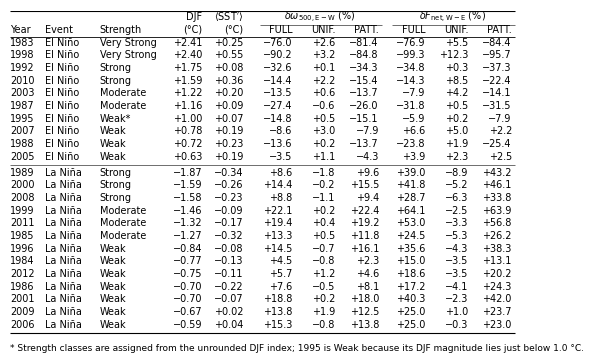

In [6]:
def signed(value, decimals):
    return f"{value:+.{decimals}f}".replace("-", "\u2212")   # true minus sign


pct_cols = [c for c in table_s1.columns if c.endswith("(%)")]
rows = []
for _, r in table_s1.iterrows():
    strength = r["Strength"] + ("*" if r["Year"] in boundary_years else "")
    rows.append([str(r["Year"]), r["Event"], strength,
                 signed(r["DJF Nino3.4 (degC)"], 2), signed(r["UNIFORM SST anomaly (degC)"], 2)]
                + [signed(r[c], 1) for c in pct_cols])

# column right edges (left edge for the three text columns), in axes fraction
X_TEXT = [0.000, 0.065, 0.165]
X_NUM = [0.355, 0.430, 0.520, 0.600, 0.680, 0.765, 0.845, 0.925]
ROW_H = 1.0 / (len(rows) + 3.2)
n_el_nino = int((table_s1["Event"] == "El Niño").sum())

fig_h = 0.155 * (len(rows) + 3.2) + (0.25 if FOOTNOTE else 0)
fig, ax = plt.subplots(figsize=(FIG_WIDTH, fig_h))
ax.set_axis_off()
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

def y_of(i):            # baseline of row i (0 = first header line)
    return 1 - (i + 0.75) * ROW_H

def rule(y, x0=0.0, x1=0.93, lw=0.6):
    ax.plot([x0, x1], [y, y], color="black", linewidth=lw, solid_capstyle="butt")

# header, two lines
rule(1.0, lw=0.8)
ax.text((X_NUM[2] + X_NUM[4]) / 2 - 0.03, y_of(0), r"$\delta\omega_{500,\mathrm{E-W}}$ (%)", ha="center", va="baseline")
ax.text((X_NUM[5] + X_NUM[7]) / 2 - 0.03, y_of(0), r"$\delta F_{\mathrm{net,W-E}}$ (%)", ha="center", va="baseline")
ax.text(X_NUM[0], y_of(0), "DJF", ha="right", va="baseline")
ax.text(X_NUM[1], y_of(0), r"$\langle\mathrm{SST}'\rangle$", ha="right", va="baseline")
rule(1 - 1.15 * ROW_H, X_NUM[2] - 0.06, X_NUM[4] + 0.005, lw=0.4)
rule(1 - 1.15 * ROW_H, X_NUM[5] - 0.06, X_NUM[7] + 0.005, lw=0.4)
for x, label in zip(X_TEXT, ["Year", "Event", "Strength"]):
    ax.text(x, y_of(1), label, ha="left", va="baseline")
for x, label in zip(X_NUM, ["(°C)", "(°C)", "FULL", "UNIF.", "PATT.", "FULL", "UNIF.", "PATT."]):
    ax.text(x, y_of(1), label, ha="right", va="baseline")
rule(1 - 2.05 * ROW_H)

# body
for i, row in enumerate(rows):
    line = i + 2 + (0.25 if i >= n_el_nino else 0)
    for x, cell in zip(X_TEXT, row[:3]):
        ax.text(x, y_of(line), cell, ha="left", va="baseline")
    for x, cell in zip(X_NUM, row[3:]):
        ax.text(x, y_of(line), cell, ha="right", va="baseline", fontfamily="DejaVu Sans")
    if i == n_el_nino - 1:
        rule(y_of(line) - 0.42 * ROW_H, lw=0.4)
y_bottom = y_of(len(rows) + 1.25) - 0.42 * ROW_H
rule(y_bottom, lw=0.8)
if FOOTNOTE:
    ax.text(0.0, y_bottom - 0.9 * ROW_H, FOOTNOTE, ha="left", va="top", fontsize=6.5)

for ext in ["png", "pdf"]:
    out_path = os.path.join(cfg.FIGURES_DIR, f"tableS1_event_summary.{ext}")
    fig.savefig(out_path, dpi=300, bbox_inches="tight", pad_inches=0.03)
    print("saved", os.path.relpath(out_path, cfg.REPO_ROOT))
plt.show()

## Step 6 — numbers quoted in the text

In [7]:
for year in [1983, 1998]:
    r = table_s1.set_index("Year").loc[year]
    print(f"{year}: <SST'> = {r['UNIFORM SST anomaly (degC)']:+.2f} degC, "
          f"d_omega FULL = {r['d_omega FULL (%)']:+.1f} %, UNIFORM = {r['d_omega UNIFORM (%)']:+.1f} %")

1983: <SST'> = +0.25 degC, d_omega FULL = -76.0 %, UNIFORM = +2.6 %
1998: <SST'> = +0.55 degC, d_omega FULL = -90.2 %, UNIFORM = +3.2 %
